# Milestone 2: Creating Static Visualizations

This notebook uses `data/weather_14-25_v2.csv` to create graphs and visualizations.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [13]:
#import data
weather = pd.read_csv("../data/weather_14-25_v2.csv", parse_dates=['DATE'])

In [14]:
weather['SEASON'] = pd.Categorical(weather.SEASON, categories=['Spring', 'Summer', 'Fall', 'Winter'], ordered=True)
weather['STATION'] = pd.Categorical(weather.STATION, categories=['Dublin', 'Toronto', 'San Jose'])
weather['YEAR'] = weather['DATE'].dt.year
weather['MONTH']=weather['DATE'].dt.month
weather.head()

,STATION,DATE,AWND,PRCP,SNOW,TAVG,TMAX,TMIN,SEASON,YEAR,MONTH
0,Dublin,2014-01-01,NaN,3.8,NaN,6.3,10.5,2.7,Winter,2014,1
1,Dublin,2014-01-02,NaN,3.7,NaN,6.8,10.3,4.7,Winter,2014,1
2,Dublin,2014-01-03,NaN,3.1,NaN,6.8,8.3,3.6,Winter,2014,1
3,Dublin,2014-01-04,NaN,0.0,NaN,3.9,7.2,1.2,Winter,2014,1
4,Dublin,2014-01-05,NaN,4.4,NaN,6.9,12.8,1.2,Winter,2014,1


In [15]:
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 13143 entries, 0 to 13142
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   STATION  13143 non-null  category      
 1   DATE     13143 non-null  datetime64[us]
 2   AWND     4377 non-null   float64       
 3   PRCP     13143 non-null  float64       
 4   SNOW     4396 non-null   float64       
 5   TAVG     8598 non-null   float64       
 6   TMAX     13075 non-null  float64       
 7   TMIN     13072 non-null  float64       
 8   SEASON   13143 non-null  category      
 9   YEAR     13143 non-null  int32         
 10  MONTH    13143 non-null  int32         
dtypes: category(2), datetime64[us](1), float64(6), int32(2)
memory usage: 847.6 KB


In [16]:
# Set colorblind friendly palette
colors = sns.color_palette("colorblind")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")

# Finalized Static Visualizations

The most meaningful graphs are shown below along with design rationale

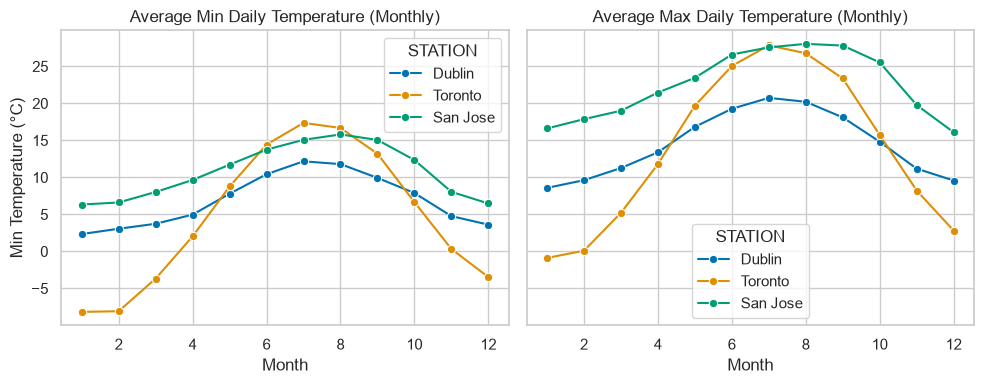

In [35]:
#Lineplot: Min and Max Daily Average Temperatures by Month and Station
mon_min = weather.groupby(["STATION","MONTH"])['TMIN'].mean().reset_index()
mon_max = weather.groupby(['STATION','MONTH'])['TMAX'].mean().reset_index()

fig, axes = plt.subplots(1,2,figsize=(10,4), sharey=True)
sns.lineplot(data=mon_min,x='MONTH',y='TMIN',marker='o',hue="STATION",ax=axes[0])
axes[0].set(title='Average Min Daily Temperature (Monthly)',xlabel='Month',ylabel='Min Temperature (°C)')

sns.lineplot(data=mon_max,x='MONTH',y='TMAX',marker='o',hue="STATION",ax=axes[1])
axes[1].set(title='Average Max Daily Temperature (Monthly)',xlabel='Month',ylabel='Max Temperature (°C)')

#plt.savefig("../visuals/monthly_lineplot.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

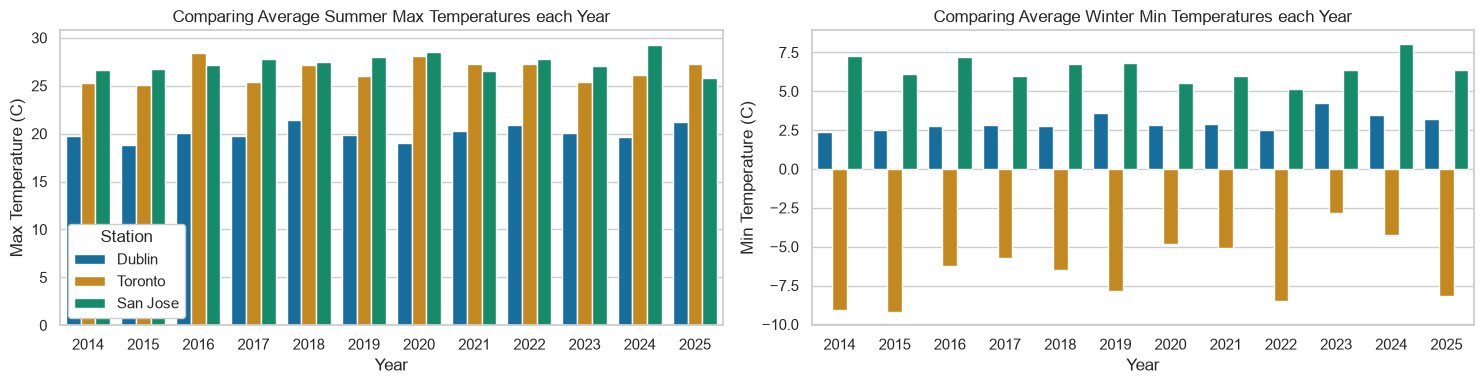

In [36]:
# Grouped Bar Graph: 
# Max average temperature grouped by Station for Summer Season
# Min average temperature grouped by Station for Winter Season

summer_max = (weather[weather['SEASON']=='Summer'].
    groupby(['STATION','YEAR'])['TMAX'].mean().reset_index())

winter_min = (weather[weather['SEASON']=='Winter'].
    groupby(['STATION','YEAR'])['TMIN'].mean().reset_index())

fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.barplot(data=summer_max, x='YEAR',y='TMAX',hue='STATION',ax=axes[0],legend=True)
axes[0].set(title='Comparing Average Summer Max Temperatures each Year',xlabel='Year',ylabel='Max Temperature (C)')

sns.barplot(data=winter_min, x='YEAR',y='TMIN',hue='STATION',ax=axes[1], legend=False)
axes[1].set(title='Comparing Average Winter Min Temperatures each Year',xlabel='Year',ylabel='Min Temperature (C)')

axes[0].legend(title="Station", loc="lower left",framealpha=1)
plt.tight_layout()
#plt.savefig("../visuals/max_min_barplots.png", dpi=300, bbox_inches="tight")
plt.show()

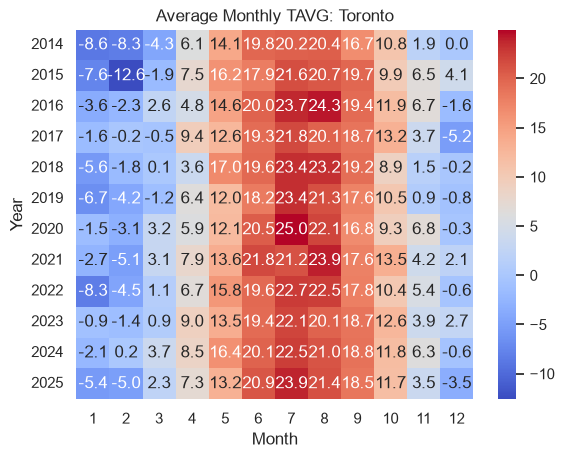

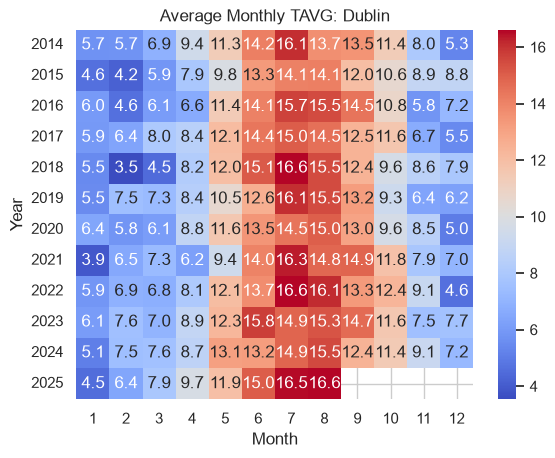

In [37]:
# Compare heatmap of Toronto and Dublin (average temperature)
#Heatmap of monthly averages across years

#Grouping
monthly_avg = weather.groupby(['STATION','YEAR','MONTH'])['TAVG'].mean().reset_index()

#Toronto Heatmap
toronto = monthly_avg[monthly_avg['STATION']=='Toronto']
t_data = toronto.pivot(index='YEAR',columns='MONTH',values='TAVG')
sns.heatmap(
    t_data,
    annot=True,
    fmt='.1f',
    cmap='coolwarm'
)
plt.title('Average Monthly TAVG: Toronto')
plt.xlabel('Month')
plt.ylabel('Year')
#plt.savefig("../visuals/toronto_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

#Dublin Heatmap
dublin = monthly_avg[monthly_avg['STATION']=='Dublin']
d_data = dublin.pivot(index='YEAR',columns='MONTH',values='TAVG')
sns.heatmap(
    d_data,
    annot=True,
    fmt='.1f',
    cmap='coolwarm'
)
plt.title('Average Monthly TAVG: Dublin')
plt.xlabel('Month')
plt.ylabel('Year')
#plt.savefig("../visuals/dublin_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

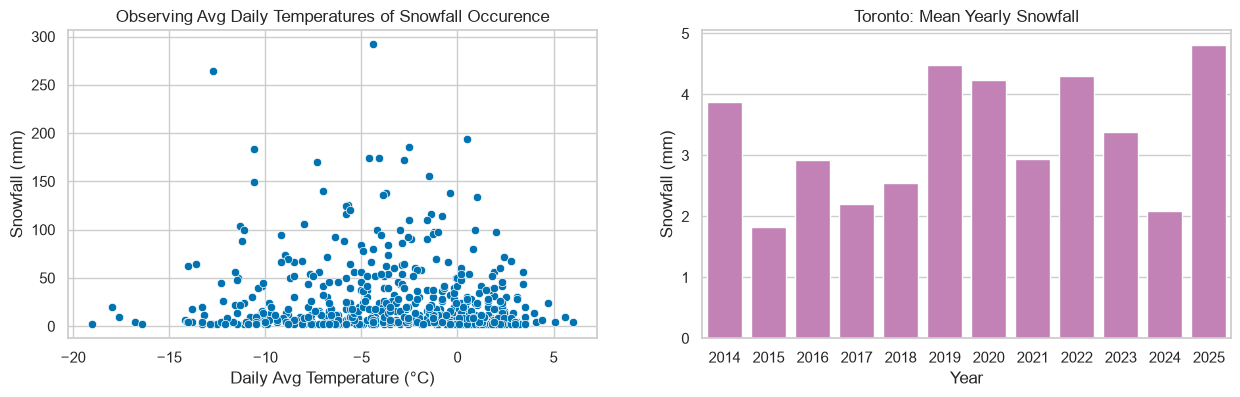

In [38]:
# Analyzing Snow patterns in Toronto
# Scatter plot of snowfall vs min temperature
# Barplot of mean yearly average snowfall in Toronto
snow = (weather[(weather['STATION']=='Toronto') & 
    (weather['SEASON']!='Summer') & (weather['SNOW']>0)])

yearly_snow = weather[weather['STATION']=='Toronto'].groupby('YEAR')['SNOW'].mean().reset_index()

fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.scatterplot(data=snow, x='TAVG',y='SNOW',ax=axes[0])
axes[0].set(title='Observing Avg Daily Temperatures of Snowfall Occurence'
            ,ylabel='Snowfall (mm)',xlabel='Daily Avg Temperature (°C)')

sns.barplot(data=yearly_snow, x='YEAR',y='SNOW',ax=axes[1], color=colors[4])
axes[1].set(title='Toronto: Mean Yearly Snowfall',xlabel='Year',ylabel='Snowfall (mm)')
#plt.savefig("../visuals/toronto_snow.png", dpi=300, bbox_inches="tight")
plt.show()

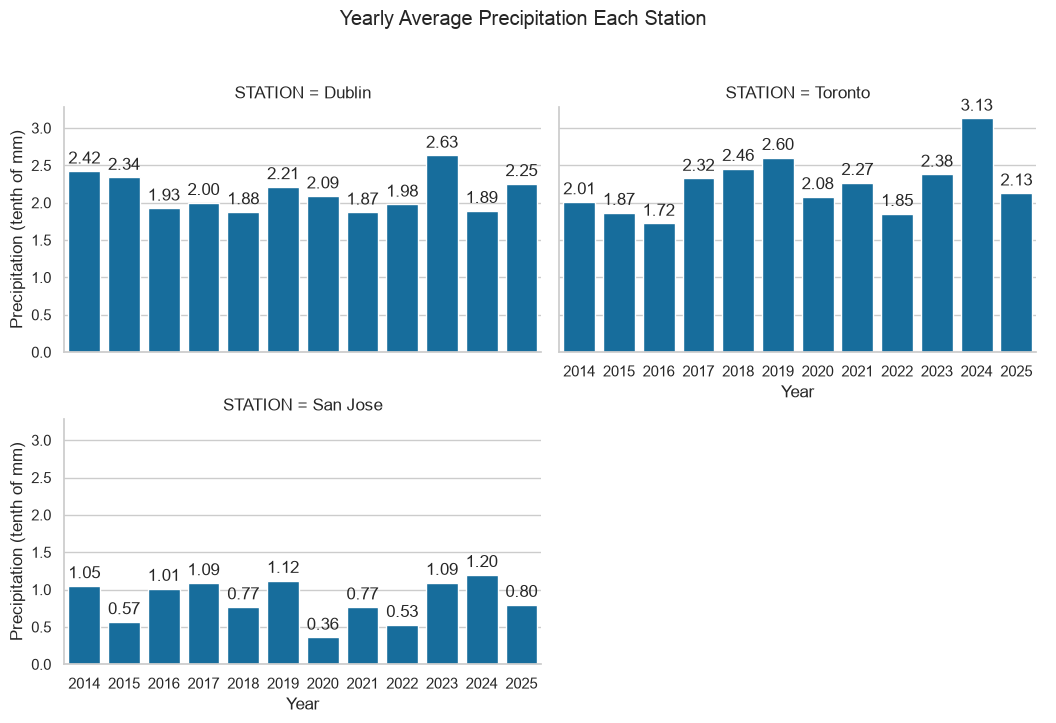

In [39]:
# Faceted Graph of monthly precipitation average of each station

g4 = sns.catplot(data=weather, x='YEAR',y='PRCP',
                 col='STATION',kind='bar',col_wrap=2,
                 height=3.5,aspect=1.5,errorbar=None,)
g4.figure.suptitle("Yearly Average Precipitation Each Station", y=1.03)
g4.set_axis_labels("Year","Precipitation (tenth of mm)")

#add values on top of the bars
for ax in g4.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3)
plt.tight_layout()
#g4.savefig("../visuals/prcp_yearly.png", dpi=300, bbox_inches="tight")
plt.show()

### Story
- In comparing the seasonal min and max temperatures, Toronto has much higher flunctations in temperature. San Jose has higher temperatures on average than the other locations, especially in the summer. Meanwhile, Dublin's temperatures are always lower than San Jose. However, Toronto has lower temperatures than the other stations from October to April but temperatures can peak up to San Jose (around July) in summer months
- Average yearly minimum winter temperatures are much lower for Toronto than the other stations but average yearly maximum temperature between San Jose and Toronto are very close
- 2015 had some of the lowest averages for winter months
- For Toronto, 2025 had the highest average snowfall but 2019, 2020, and 2022 also had higher average snowfall. On the heatmap, these years were colder than adjacent years that did not have as much snowfall. Similarly, when comparing snowfall with daily average temperature, there was no linear relationship. Instead, there was higher amounts of snowfall between -10C and 3C
- San Jose had the lowest average precipitation for all years while Dublin and Toronto had overlapping averages

### Design Rationale:
Design
- Line plot was used so that 3 stations on the same graph would be more visible in showing different temperatures
- Grouped barplots was used to show categorical differences yearly
- Heatmap was a good way to show the distribution of temperatures across the span of months and years. It shows the varying degrees in a spectrum of reds and blues, which is good for showing hot and cold temperatures
- The scatterplot was used to find correlation between snowfall and temperature while the bar graph was used to compare categories (snowfall for different years)
- The faceted bar graphs were used to create 3 distinct graphs for each station and compare yearly precipitation measurements

### Accessibility Notes
All of the graphs used a colorblind friendly palette, had appropriate titles and axes labels, and a custom placed legend if needed. The precipitation graph had additional labeling of the precipitation values to make the graph more clear. Also, contrasting colors were used (blue vs. pink, blue vs. red, etc.)

### Bias Critique
- Our data was extremely large, with thousands of observations for each station, spanning over a decade. The plots above focused on getting a bigger picture of the data, so most of the values were averages. For overall yearly or monthly values, extreme values can be hidden and montly or weekly variation can be lost. 
- For example, even though we found that 2025 had the highest average snowfall compared to other years in our dataset but it doesn't account for the amount or duration of snowfall within certain months.
- Certain graphs could have gone more in depth with specific months or years.

# Other Exploratory Visualization


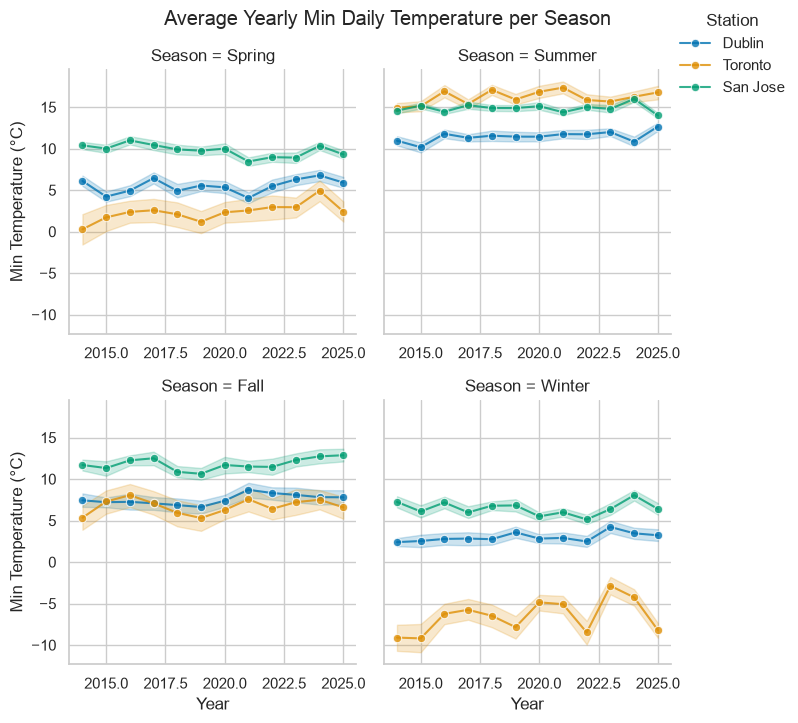

In [22]:
g = sns.FacetGrid(weather, col="SEASON", col_wrap=2,height=3.5,sharex=False, sharey=True)
g.map_dataframe(sns.lineplot,marker='o',x="YEAR", y="TMIN", hue='STATION', alpha=0.8)
g.set_axis_labels("Year", "Min Temperature (°C)")
g.set_titles("Season = {col_name}")
g.figure.suptitle("Average Yearly Min Daily Temperature per Season", y=1.03)
g.add_legend(title='Station',loc='upper right')
plt.show()


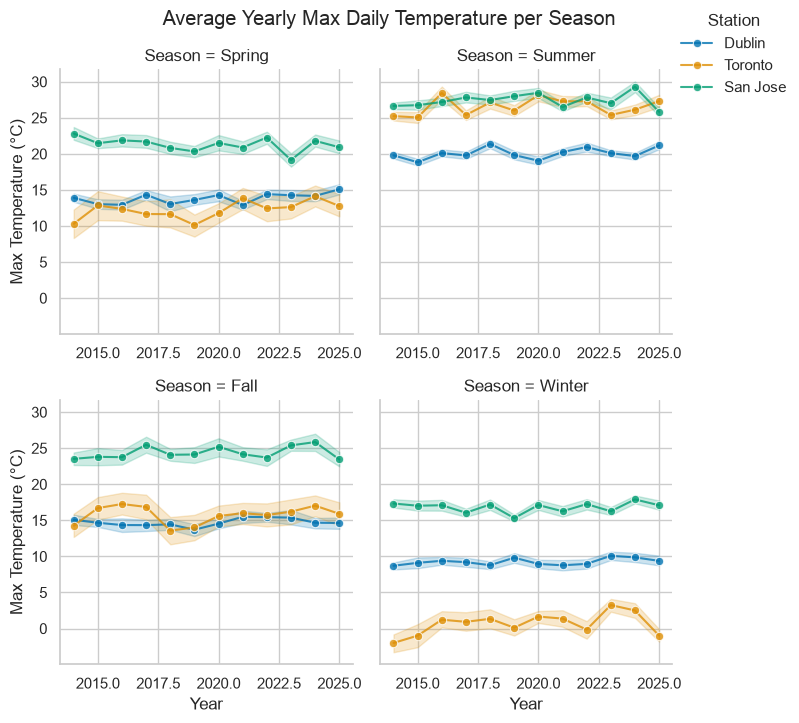

In [23]:
g = sns.FacetGrid(weather, col="SEASON", col_wrap=2,height=3.5,sharex=False, sharey=True)
g.map_dataframe(sns.lineplot,marker='o',x="YEAR", y="TMAX", hue='STATION', alpha=0.8)
g.set_axis_labels("Year", "Max Temperature (°C)")
g.set_titles("Season = {col_name}")
g.figure.suptitle("Average Yearly Max Daily Temperature per Season", y=1.03)
g.add_legend(title='Station',loc='upper right')
plt.show()

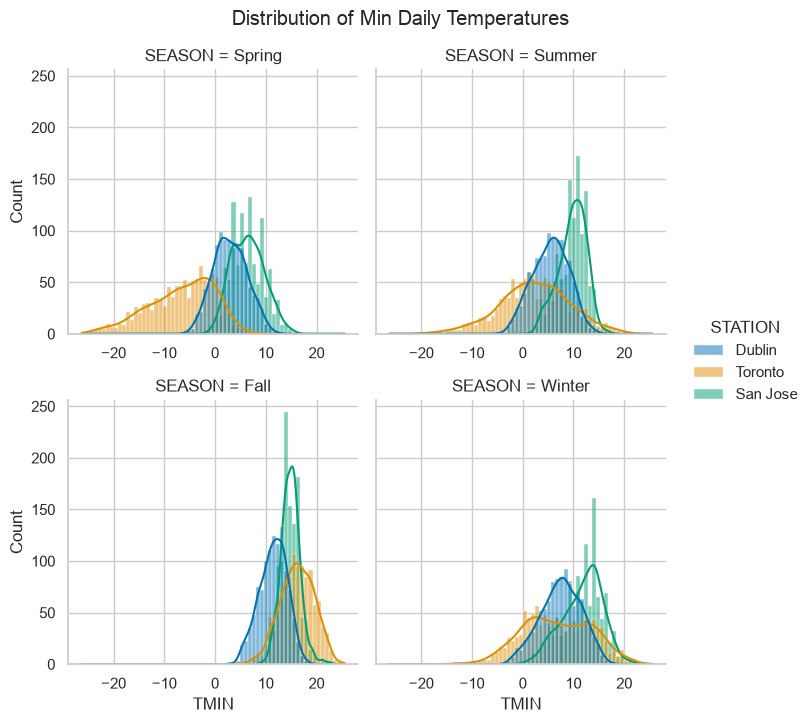

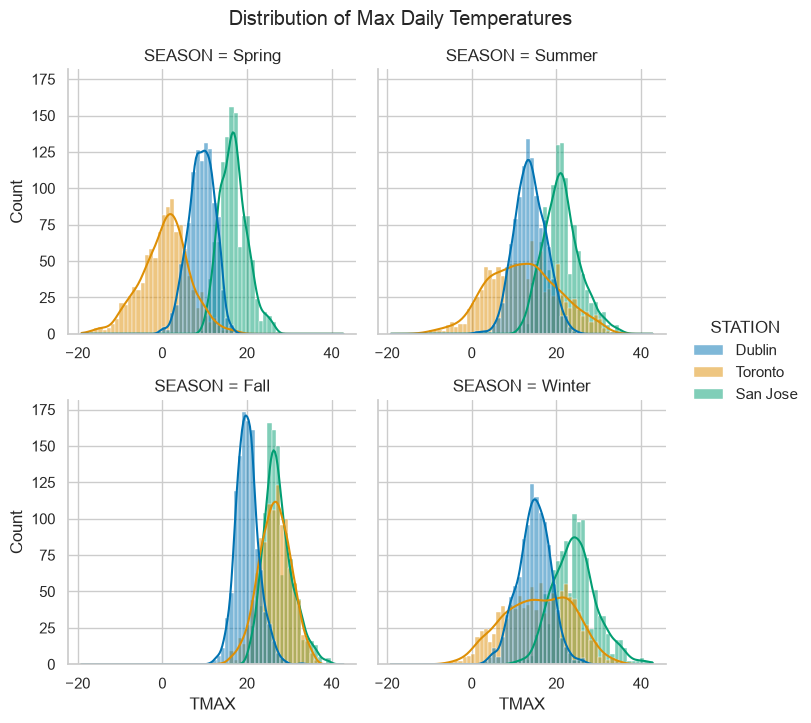

In [24]:
#histogram of weather distribution?? --> Overall for all 3
g2 = sns.displot(data=weather, x="TMIN", col="SEASON",
                 kind="hist", hue='STATION', kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g2.figure.suptitle("Distribution of Min Daily Temperatures", y=1.03)

# Max Temperature
g3 = sns.displot(data=weather, x="TMAX", col="SEASON",
                 kind="hist", hue='STATION', kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g3.figure.suptitle("Distribution of Max Daily Temperatures", y=1.03)
plt.show()

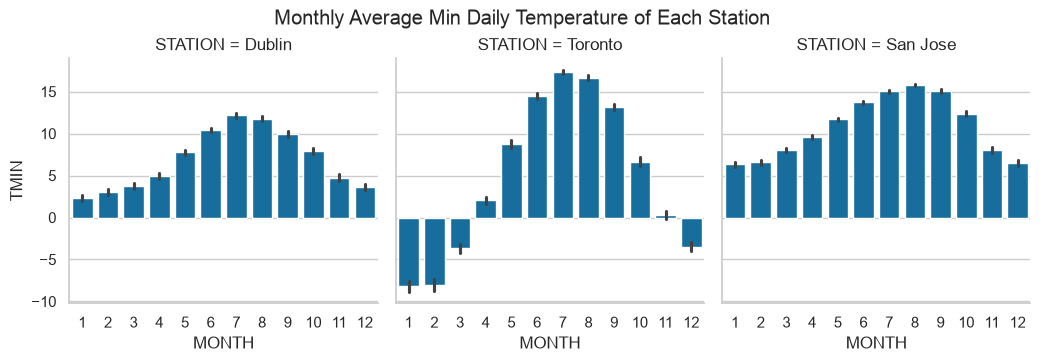

In [25]:
g4 = sns.catplot(data=weather, x='MONTH',y='TMIN'
                ,col='STATION',kind='bar',col_wrap=3,height=3.5)
g4.figure.suptitle("Monthly Average Min Daily Temperature of Each Station", y=1.03)
plt.show()

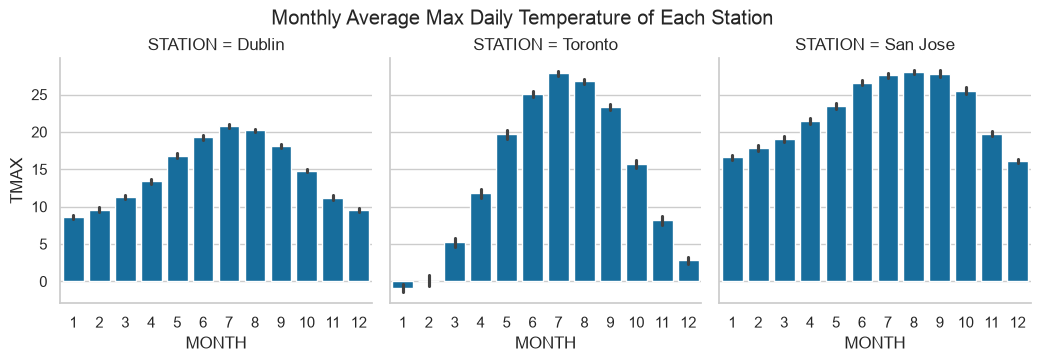

In [26]:
g4 = sns.catplot(data=weather, x='MONTH',y='TMAX'
                ,col='STATION',kind='bar',col_wrap=3,height=3.5)
g4.figure.suptitle("Monthly Average Max Daily Temperature of Each Station", y=1.03)
plt.show()

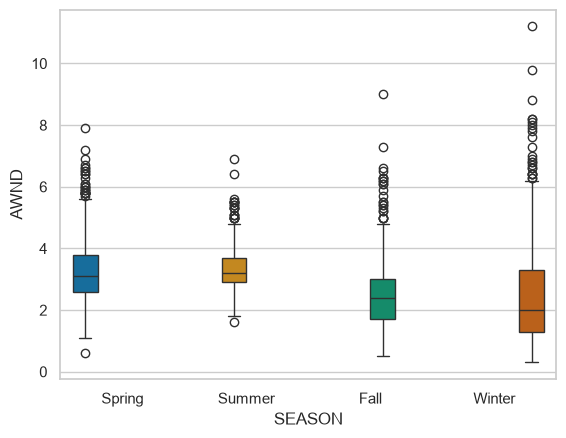

In [27]:
#AWND
sj = weather[(weather['STATION']=='San Jose')]
sns.boxplot(data=sj, x='SEASON',y='AWND',hue='SEASON')
plt.show()

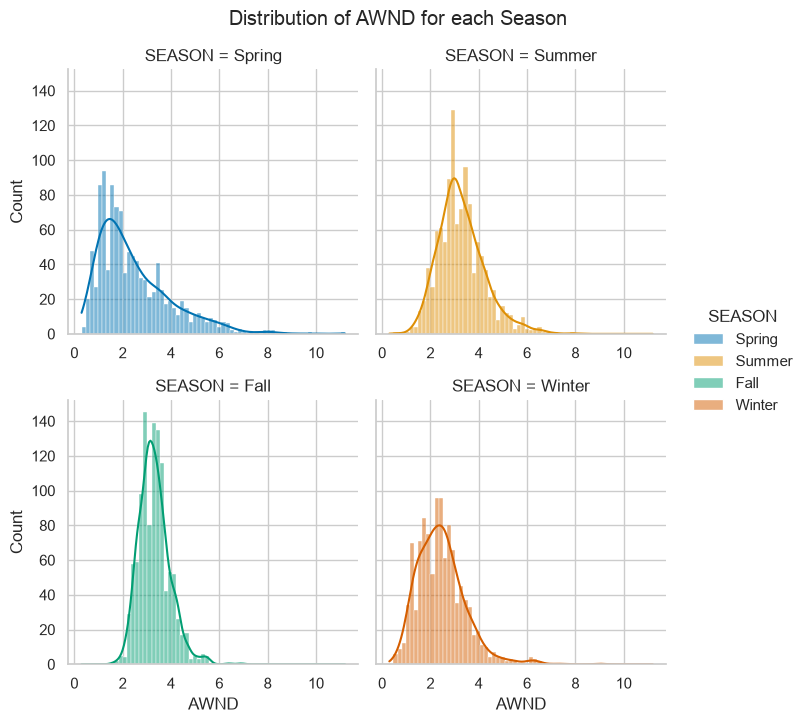

In [28]:

g3 = sns.displot(data=sj, x="AWND", col="SEASON", hue='SEASON',
                 kind="hist", kde=True, col_wrap=2,height=3.5
                ,facet_kws={"sharex": False, "sharey": True})
g3.figure.suptitle("Distribution of AWND for each Season", y=1.03)
plt.show()